In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\Anet\anaconda3\python.exe
Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [9]:
from pathlib import Path
import pandas as pd

file_path = Path("P5-Cardio Vascular Risk Prediction.csv")

if not file_path.exists():
    print("Dataset not found. Current notebook directory:", Path.cwd())
else:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())

Dataset loaded successfully!
Dataset shape: (3390, 17)


,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,64,2.0,F,YES,3.0,0.0,0,0,0,221.0,148.0,85.0,NaN,90.0,80.0,1
1,1,36,4.0,M,NO,0.0,0.0,0,1,0,212.0,168.0,98.0,29.77,72.0,75.0,0
2,2,46,1.0,F,YES,10.0,0.0,0,0,0,250.0,116.0,71.0,20.35,88.0,94.0,0
3,3,50,1.0,M,YES,20.0,0.0,0,1,0,233.0,158.0,88.0,28.26,68.0,94.0,1
4,4,64,1.0,F,YES,30.0,0.0,0,0,0,241.0,136.5,85.0,26.42,70.0,77.0,0


In [10]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

Number of rows: 3390
Number of columns: 17

Column names:
['id', 'age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3390 entries, 0 to 3389
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               3390 non-null   int64  
 1   age              3390 non-null   int64  
 2   education        3303 non-null   float64
 3   sex              3390 non-null   object 
 4   is_smoking       3390 non-null   object 
 5   cigsPerDay       3368 non-null   float64
 6   BPMeds           3346 non-null   float64
 7   prevalentStroke  3390 non-null   int64  
 8   prevalentHyp     3390 non-null   int64  
 9   diabetes         3390 non-null   int64  
 10  totChol          3352 non-null   float64
 11  sysBP            

In [15]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage (%)": (missing / len(df) * 100).round(2)
})

missing_table = missing_table[missing_table["Missing Values"] > 0]
missing_table.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Percentage (%)
glucose,304,8.97
education,87,2.57
BPMeds,44,1.30
totChol,38,1.12
cigsPerDay,22,0.65
BMI,14,0.41
heartRate,1,0.03


In [16]:
print("CHD outcome counts:")
print(df["TenYearCHD"].value_counts())

print("\nCHD outcome percentages:")
print((df["TenYearCHD"].value_counts(normalize=True) * 100).round(2))

CHD outcome counts:
TenYearCHD
0    2879
1     511
Name: count, dtype: int64

CHD outcome percentages:
TenYearCHD
0    84.93
1    15.07
Name: proportion, dtype: float64


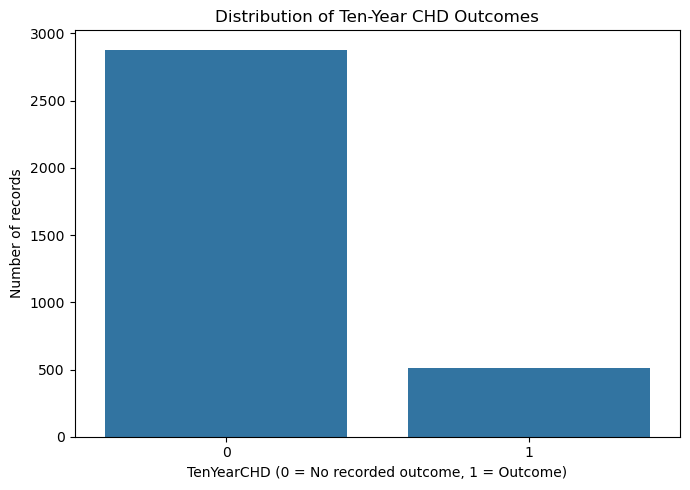

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="TenYearCHD")

plt.title("Distribution of Ten-Year CHD Outcomes")
plt.xlabel("TenYearCHD (0 = No recorded outcome, 1 = Outcome)")
plt.ylabel("Number of records")

plt.tight_layout()
plt.show()

In [18]:
# Check the target column
print("Target column:", "TenYearCHD")

# Check unique target values
print("Unique target values:", sorted(df["TenYearCHD"].dropna().unique()))

# Check missing values in the target
print("Missing target values:", df["TenYearCHD"].isnull().sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check identifier column
print("ID column exists:", "id" in df.columns)

Target column: TenYearCHD
Unique target values: [np.int64(0), np.int64(1)]
Missing target values: 0
Duplicate rows: 0
ID column exists: True


In [23]:
df.dtypes

id                   int64
age                  int64
education          float64
sex                 object
is_smoking          object
cigsPerDay         float64
BPMeds             float64
prevalentStroke      int64
prevalentHyp         int64
diabetes             int64
totChol            float64
sysBP              float64
diaBP              float64
BMI                float64
heartRate          float64
glucose            float64
TenYearCHD           int64
dtype: object

In [19]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Remove duplicate rows if any exist
df_clean = df_clean.drop_duplicates()

# Check for missing target values
df_clean = df_clean.dropna(subset=["TenYearCHD"])

print("Original dataset shape:", df.shape)
print("After removing duplicates and missing targets:", df_clean.shape)

print("\nMissing values remaining:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Original dataset shape: (3390, 17)
After removing duplicates and missing targets: (3390, 17)

Missing values remaining:
education      87
cigsPerDay     22
BPMeds         44
totChol        38
BMI            14
heartRate       1
glucose       304
dtype: int64


In [20]:
# Target: the outcome we want the model to learn
target = "TenYearCHD"

# Remove the target and ID from the input features
X = df_clean.drop(columns=["TenYearCHD", "id"], errors="ignore")
y = df_clean[target].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (3390, 15)
Target shape: (3390,)

Features used:
['age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

Target distribution:
TenYearCHD
0    2879
1     511
Name: count, dtype: int64


In [24]:
print("Numerical columns:")
print(X.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

Numerical columns:
['age', 'education', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

Categorical columns:
['sex', 'is_smoking']


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (2712, 15)
Testing features: (678, 15)

Training target distribution:
TenYearCHD
0    0.849
1    0.151
Name: proportion, dtype: float64

Testing target distribution:
TenYearCHD
0    0.85
1    0.15
Name: proportion, dtype: float64


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify columns by their data types
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'education', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

Categorical features: ['sex', 'is_smoking']


In [27]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [28]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.709
Precision: 0.291
Recall   : 0.647
F1-score : 0.401
ROC-AUC  : 0.722

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.72      0.81       576
           1       0.29      0.65      0.40       102

    accuracy                           0.71       678
   macro avg       0.61      0.68      0.60       678
weighted avg       0.83      0.71      0.75       678

Confusion matrix:
[[415 161]
 [ 36  66]]


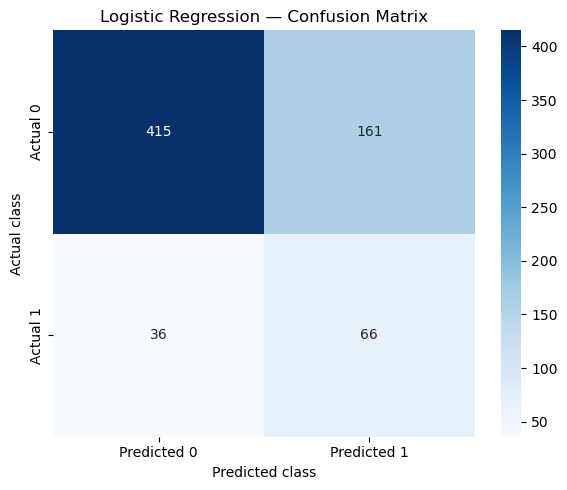

In [32]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, rf_pred, zero_division=0), 3))
print("F1-score :", round(f1_score(y_test, rf_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 3))

print("\nClassification report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy : 0.836
Precision: 0.355
Recall   : 0.108
F1-score : 0.165
ROC-AUC  : 0.686

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       576
           1       0.35      0.11      0.17       102

    accuracy                           0.84       678
   macro avg       0.61      0.54      0.54       678
weighted avg       0.78      0.84      0.80       678

Confusion matrix:
[[556  20]
 [ 91  11]]


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, rf_pred, zero_division=0), 3))
print("F1-score :", round(f1_score(y_test, rf_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 3))

print("\nClassification report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy : 0.836
Precision: 0.355
Recall   : 0.108
F1-score : 0.165
ROC-AUC  : 0.686

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       576
           1       0.35      0.11      0.17       102

    accuracy                           0.84       678
   macro avg       0.61      0.54      0.54       678
weighted avg       0.78      0.84      0.80       678

Confusion matrix:
[[556  20]
 [ 91  11]]


In [36]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(comparison.round(3))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.709,0.836
1,Precision,0.291,0.355
2,Recall,0.647,0.108
3,F1-score,0.401,0.165
4,ROC-AUC,0.722,0.686


In [37]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

,Feature,Importance,Std
0,age,0.1361,0.0068
4,cigsPerDay,0.0161,0.0064
10,sysBP,0.0121,0.0043
2,sex,0.0075,0.0052
14,glucose,0.0050,0.0044
3,is_smoking,0.0041,0.0044
6,prevalentStroke,0.0038,0.0012
9,totChol,0.0010,0.0040
8,diabetes,0.0007,0.0008
5,BPMeds,0.0003,0.0003


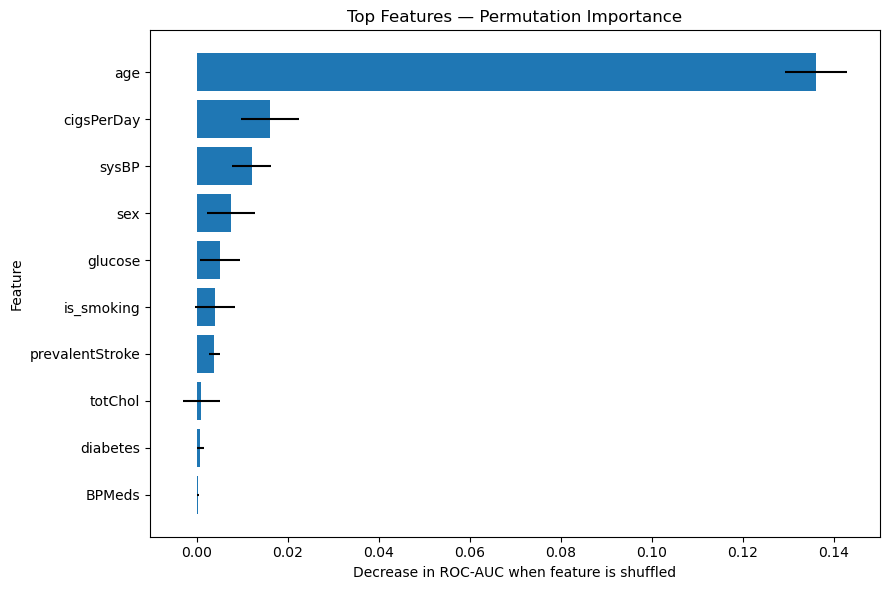

In [38]:
top_features = importance_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.title("Top Features — Permutation Importance")
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [39]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

importance_df.to_csv(
    output_dir / "permutation_importance.csv",
    index=False
)

print("Model comparison and feature importance saved!")

PermissionError: [WinError 5] Access is denied: '..\\outputs'